In [3]:
import os
import pandas as pd
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

In [6]:
# Credenciales leídas de variables de entorno (ver .env.example)
url = URL.create(
    drivername="mysql+pymysql",
    username=os.getenv("MYSQL_USER", "root"),
    password=os.getenv("MYSQL_PASSWORD"),
    host=os.getenv("MYSQL_HOST", "localhost"),
    port=int(os.getenv("MYSQL_PORT", "3306")),
    database=os.getenv("MYSQL_DB", "proyecto_final")
)

engine = create_engine(url)

In [7]:
with engine.connect() as conexion:
    resultado = conexion.execute(text("SELECT DATABASE();"))
    print(resultado.scalar())

proyecto_final


In [8]:
clientes = pd.read_csv("../data/clientes.csv")
productos = pd.read_csv("../data/productos.csv")
pedidos = pd.read_csv("../data/pedidos.csv")
detalle_pedido = pd.read_csv("../data/detalle_pedido.csv")

In [9]:
print("Clientes:", clientes.shape)
print("Productos:", productos.shape)
print("Pedidos:", pedidos.shape)
print("Detalle pedido:", detalle_pedido.shape)

Clientes: (300, 6)
Productos: (150, 7)
Pedidos: (3000, 5)
Detalle pedido: (7503, 6)


In [11]:
print("CLIENTES")
print(clientes.columns.tolist())

print("\nPRODUCTOS")
print(productos.columns.tolist())

print("\nPEDIDOS")
print(pedidos.columns.tolist())

print("\nDETALLE PEDIDO")
print(detalle_pedido.columns.tolist())

CLIENTES
['id_cliente', 'nombre', 'email', 'ciudad', 'segmento', 'fecha_registro']

PRODUCTOS
['id_producto', 'nombre', 'categoria', 'subcategoria', 'precio', 'costo', 'stock']

PEDIDOS
['id_pedido', 'id_cliente', 'fecha', 'estado', 'canal']

DETALLE PEDIDO
['id_detalle', 'id_pedido', 'id_producto', 'cantidad', 'precio_unit', 'subtotal']


In [12]:
print("CLIENTES")
print(clientes.dtypes)

print("\nPRODUCTOS")
print(productos.dtypes)

print("\nPEDIDOS")
print(pedidos.dtypes)

print("\nDETALLE PEDIDO")
print(detalle_pedido.dtypes)

CLIENTES
id_cliente         int64
nombre            object
email             object
ciudad            object
segmento          object
fecha_registro    object
dtype: object

PRODUCTOS
id_producto       int64
nombre           object
categoria        object
subcategoria     object
precio          float64
costo           float64
stock             int64
dtype: object

PEDIDOS
id_pedido      int64
id_cliente     int64
fecha         object
estado        object
canal         object
dtype: object

DETALLE PEDIDO
id_detalle       int64
id_pedido        int64
id_producto      int64
cantidad         int64
precio_unit    float64
subtotal       float64
dtype: object


In [13]:
clientes["fecha_registro"] = pd.to_datetime(
    clientes["fecha_registro"]
).dt.date

pedidos["fecha"] = pd.to_datetime(
    pedidos["fecha"]
).dt.date

In [14]:
print(clientes[["id_cliente", "fecha_registro"]].head())
print()
print(pedidos[["id_pedido", "fecha"]].head())

   id_cliente fecha_registro
0           1     2025-04-30
1           2     2024-11-24
2           3     2024-03-23
3           4     2024-12-04
4           5     2024-09-05

   id_pedido       fecha
0         39  2025-01-01
1        136  2025-01-01
2        181  2025-01-01
3        334  2025-01-01
4       1085  2025-01-01


In [15]:
tablas = [
    "clientes",
    "productos",
    "pedidos",
    "detalle_pedido"
]

with engine.connect() as conexion:
    for tabla in tablas:
        cantidad = conexion.execute(
            text(f"SELECT COUNT(*) FROM {tabla}")
        ).scalar()

        print(tabla, cantidad)

clientes 0
productos 0
pedidos 0
detalle_pedido 0


In [16]:
clientes.to_sql(
    name="clientes",
    con=engine,
    if_exists="append",
    index=False
)

300

In [17]:
with engine.connect() as conexion:
    cantidad = conexion.execute(
        text("SELECT COUNT(*) FROM clientes")
    ).scalar()

print("Clientes en MySQL:", cantidad)

Clientes en MySQL: 300


In [18]:
productos.to_sql(
    name="productos",
    con=engine,
    if_exists="append",
    index=False
)

150

In [19]:
with engine.connect() as conexion:
    cantidad = conexion.execute(
        text("SELECT COUNT(*) FROM productos")
    ).scalar()

print("Productos en MySQL:", cantidad)

Productos en MySQL: 150


In [20]:
pedidos.to_sql(
    name="pedidos",
    con=engine,
    if_exists="append",
    index=False
)

3000

In [21]:
with engine.connect() as conexion:
    cantidad = conexion.execute(
        text("SELECT COUNT(*) FROM pedidos")
    ).scalar()

print("Pedidos en MySQL:", cantidad)

Pedidos en MySQL: 3000


In [22]:
detalle_pedido.to_sql(
    name="detalle_pedido",
    con=engine,
    if_exists="append",
    index=False
)

7503

In [23]:
with engine.connect() as conexion:
    cantidad = conexion.execute(
        text("SELECT COUNT(*) FROM detalle_pedido")
    ).scalar()

print("Detalle pedido en MySQL:", cantidad)

Detalle pedido en MySQL: 7503


In [24]:
dataframes = {
    "clientes": clientes,
    "productos": productos,
    "pedidos": pedidos,
    "detalle_pedido": detalle_pedido
}

with engine.connect() as conexion:
    for tabla, df in dataframes.items():

        filas_csv = len(df)

        filas_mysql = conexion.execute(
            text(f"SELECT COUNT(*) FROM {tabla}")
        ).scalar()

        print(
            f"{tabla}: CSV = {filas_csv} | MySQL = {filas_mysql}"
        )

clientes: CSV = 300 | MySQL = 300
productos: CSV = 150 | MySQL = 150
pedidos: CSV = 3000 | MySQL = 3000
detalle_pedido: CSV = 7503 | MySQL = 7503


In [25]:
with engine.connect() as conexion:
    for tabla, df in dataframes.items():

        filas_csv = len(df)

        filas_mysql = conexion.execute(
            text(f"SELECT COUNT(*) FROM {tabla}")
        ).scalar()

        estado = "OK" if filas_csv == filas_mysql else "ERROR"

        print(
            f"{tabla}: CSV = {filas_csv} | "
            f"MySQL = {filas_mysql} | {estado}"
        )

clientes: CSV = 300 | MySQL = 300 | OK
productos: CSV = 150 | MySQL = 150 | OK
pedidos: CSV = 3000 | MySQL = 3000 | OK
detalle_pedido: CSV = 7503 | MySQL = 7503 | OK


In [28]:
#FASE 4 DESDE AQUÍ
df_ped = pd.read_sql(
    "SELECT * FROM pedidos",
    engine,
    parse_dates=["fecha"]
)

df_det = pd.read_sql(
    "SELECT * FROM detalle_pedido",
    engine
)

df_cli = pd.read_sql(
    "SELECT * FROM clientes",
    engine,
    parse_dates=["fecha_registro"]
)

In [29]:
print("Pedidos:", df_ped.shape)
print("Detalle pedido:", df_det.shape)
print("Clientes:", df_cli.shape)

Pedidos: (3000, 5)
Detalle pedido: (7503, 6)
Clientes: (300, 6)


In [30]:
def calcular_kpis(df_ped, df_det, df_cli):
    """Calcula el set estándar de KPIs de negocio."""

    ingresos = df_det["subtotal"].sum()

    n_pedidos = df_ped["id_pedido"].nunique()

    aov = ingresos / n_pedidos if n_pedidos else 0

    cancel = (df_ped["estado"] == "cancelado").mean()

    conteo = df_ped.groupby("id_cliente")["id_pedido"].count()

    recurrencia = (
        (conteo > 1).sum() / conteo.shape[0]
        if conteo.shape[0] else 0
    )

    return {
        "ingresos_totales": round(ingresos, 2),
        "ticket_promedio": round(aov, 2),
        "tasa_cancelacion": round(cancel, 4),
        "recurrencia": round(recurrencia, 4)
    }

In [31]:
kpis = calcular_kpis(
    df_ped,
    df_det,
    df_cli
)

kpis

{'ingresos_totales': np.float64(10966816.6),
 'ticket_promedio': np.float64(3655.61),
 'tasa_cancelacion': np.float64(0.1713),
 'recurrencia': np.float64(1.0)}

In [32]:
print(
    f"Ingresos totales: S/. {kpis['ingresos_totales']:,.2f}"
)

print(
    f"AOV: S/. {kpis['ticket_promedio']:,.2f}"
)

print(
    f"Tasa de cancelación: {kpis['tasa_cancelacion']:.1%}"
)

print(
    f"Tasa de recurrencia: {kpis['recurrencia']:.1%}"
)

Ingresos totales: S/. 10,966,816.60
AOV: S/. 3,655.61
Tasa de cancelación: 17.1%
Tasa de recurrencia: 100.0%


In [34]:
df_tiempo = pd.read_sql(
    """
    SELECT dp.subtotal, p.fecha
    FROM detalle_pedido dp
    JOIN pedidos p
        ON dp.id_pedido = p.id_pedido
    """,
    engine,
    parse_dates=["fecha"]
)

df_tiempo.head()

,subtotal,fecha
0,2235.86,2025-08-25
1,206.36,2025-12-12
2,392.66,2025-12-12
3,1381.50,2025-10-07
4,639.80,2025-10-07


In [35]:
print(df_tiempo.shape)
print(df_tiempo.dtypes)

(7503, 2)
subtotal           float64
fecha       datetime64[ns]
dtype: object


In [36]:
df_tiempo = df_tiempo.set_index("fecha")

df_tiempo.head()

,subtotal
fecha,
2025-08-25,2235.86
2025-12-12,206.36
2025-12-12,392.66
2025-10-07,1381.50
2025-10-07,639.80


In [38]:
ing_mensual = (
    df_tiempo["subtotal"]
    .resample("ME")
    .sum()
)

print(ing_mensual)

fecha
2025-01-31    839324.74
2025-02-28    849189.14
2025-03-31    902330.46
2025-04-30    910104.18
2025-05-31    962540.58
2025-06-30    813209.01
2025-07-31    888470.04
2025-08-31    894262.78
2025-09-30    982077.96
2025-10-31    989543.79
2025-11-30    973187.30
2025-12-31    962576.62
Freq: ME, Name: subtotal, dtype: float64


In [39]:
media_movil = ing_mensual.rolling(3).mean()

print(media_movil)

fecha
2025-01-31              NaN
2025-02-28              NaN
2025-03-31    863614.780000
2025-04-30    887207.926667
2025-05-31    924991.740000
2025-06-30    895284.590000
2025-07-31    888073.210000
2025-08-31    865313.943333
2025-09-30    921603.593333
2025-10-31    955294.843333
2025-11-30    981603.016667
2025-12-31    975102.570000
Freq: ME, Name: subtotal, dtype: float64


In [40]:
variacion = ing_mensual.pct_change() * 100

print(variacion)

fecha
2025-01-31          NaN
2025-02-28     1.175278
2025-03-31     6.257890
2025-04-30     0.861516
2025-05-31     5.761582
2025-06-30   -15.514314
2025-07-31     9.254820
2025-08-31     0.651990
2025-09-30     9.819841
2025-10-31     0.760207
2025-11-30    -1.652932
2025-12-31    -1.090302
Freq: ME, Name: subtotal, dtype: float64


In [41]:
resumen_mensual = pd.DataFrame({
    "ingresos": ing_mensual,
    "media_movil_3m": media_movil.round(2),
    "variacion_%": variacion.round(2)
})

resumen_mensual

,ingresos,media_movil_3m,variacion_%
fecha,,,
2025-01-31,839324.74,NaN,NaN
2025-02-28,849189.14,NaN,1.18
2025-03-31,902330.46,863614.78,6.26
2025-04-30,910104.18,887207.93,0.86
2025-05-31,962540.58,924991.74,5.76
2025-06-30,813209.01,895284.59,-15.51
2025-07-31,888470.04,888073.21,9.25
2025-08-31,894262.78,865313.94,0.65
2025-09-30,982077.96,921603.59,9.82


In [42]:
mes_pico = ing_mensual.idxmax()
ingreso_pico = ing_mensual.max()

print(
    f"Mes pico: {mes_pico.strftime('%Y-%m')}"
)

print(
    f"Ingresos del mes pico: S/. {ingreso_pico:,.2f}"
)

Mes pico: 2025-10
Ingresos del mes pico: S/. 989,543.79


In [43]:
mes_mayor_variacion = variacion.abs().idxmax()

print(
    f"Mes con mayor variación: "
    f"{mes_mayor_variacion.strftime('%Y-%m')}"
)

print(
    f"Variación: "
    f"{variacion.loc[mes_mayor_variacion]:+.2f}%"
)

Mes con mayor variación: 2025-06
Variación: -15.51%


In [45]:
df_desempeno = pd.read_sql(
    """
    SELECT
        pe.id_pedido,
        pe.canal,
        c.segmento,
        d.subtotal
    FROM pedidos pe
    JOIN clientes c
        ON pe.id_cliente = c.id_cliente
    JOIN detalle_pedido d
        ON pe.id_pedido = d.id_pedido
    """,
    engine
)

df_desempeno.head()

,id_pedido,canal,segmento,subtotal
0,446,Tienda física,Regular,2620.50
1,543,Web,Regular,1345.48
2,543,Web,Regular,3086.43
3,1530,Web,Regular,274.66
4,1546,Web,Regular,1805.94


In [47]:
desempeno_canal = (
    df_desempeno
    .groupby("canal")
    .agg(
        ingresos=("subtotal", "sum"),
        pedidos=("id_pedido", "nunique")
    )
)

desempeno_canal["AOV"] = (
    desempeno_canal["ingresos"] /
    desempeno_canal["pedidos"]
)

desempeno_canal = desempeno_canal.sort_values(
    "ingresos",
    ascending=False
)

desempeno_canal

,ingresos,pedidos,AOV
canal,,,
Web,5291638.58,1434,3690.124533
App,3874706.99,1059,3658.835685
Tienda física,1800471.03,507,3551.224911


In [48]:
desempeno_segmento = (
    df_desempeno
    .groupby("segmento")
    .agg(
        ingresos=("subtotal", "sum"),
        pedidos=("id_pedido", "nunique")
    )
)

desempeno_segmento["AOV"] = (
    desempeno_segmento["ingresos"] /
    desempeno_segmento["pedidos"]
)

desempeno_segmento = desempeno_segmento.sort_values(
    "ingresos",
    ascending=False
)

desempeno_segmento

,ingresos,pedidos,AOV
segmento,,,
Regular,5510291.73,1539,3580.436472
VIP,2858106.21,747,3826.112731
Nuevo,2598418.66,714,3639.241821


In [49]:
import matplotlib.pyplot as plt

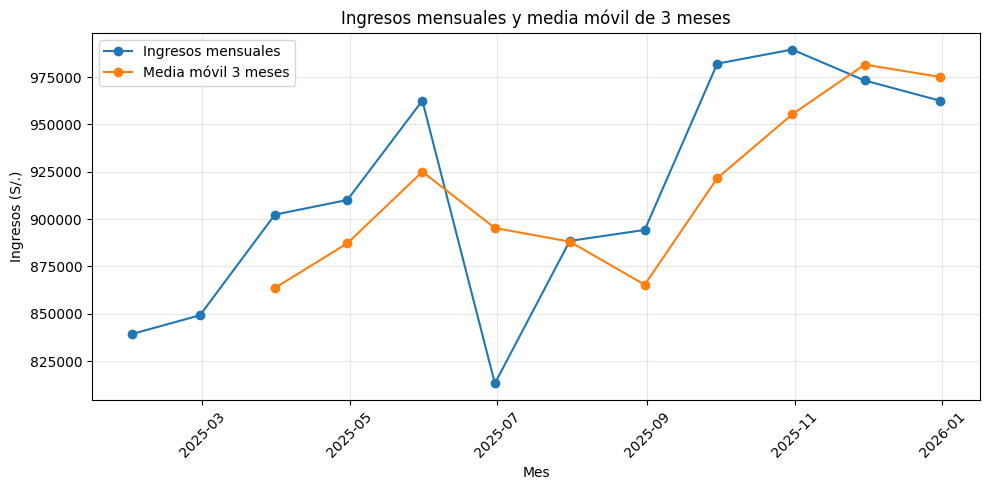

In [50]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    ing_mensual.index,
    ing_mensual.values,
    marker="o",
    label="Ingresos mensuales"
)

ax.plot(
    media_movil.index,
    media_movil.values,
    marker="o",
    label="Media móvil 3 meses"
)

ax.set_title("Ingresos mensuales y media móvil de 3 meses")
ax.set_xlabel("Mes")
ax.set_ylabel("Ingresos (S/.)")
ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

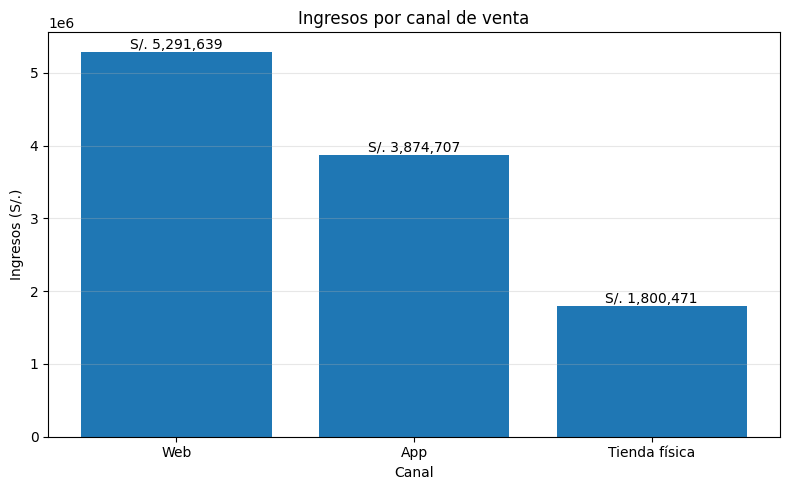

In [52]:
fig, ax = plt.subplots(figsize=(8, 5))

barras = ax.bar(
    desempeno_canal.index,
    desempeno_canal["ingresos"]
)

for barra, valor in zip(
    barras,
    desempeno_canal["ingresos"]
):
    ax.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f"S/. {valor:,.0f}",
        ha="center",
        va="bottom"
    )

ax.set_title("Ingresos por canal de venta")
ax.set_xlabel("Canal")
ax.set_ylabel("Ingresos (S/.)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
print("DESEMPEÑO POR CANAL")
display(desempeno_canal.round(2))

print("DESEMPEÑO POR SEGMENTO")
display(desempeno_segmento.round(2))

DESEMPEÑO POR CANAL


,ingresos,pedidos,AOV
canal,,,
Web,5291638.58,1434,3690.12
App,3874706.99,1059,3658.84
Tienda física,1800471.03,507,3551.22


DESEMPEÑO POR SEGMENTO


,ingresos,pedidos,AOV
segmento,,,
Regular,5510291.73,1539,3580.44
VIP,2858106.21,747,3826.11
Nuevo,2598418.66,714,3639.24
